In [81]:
import os
import h3
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
import contextily as cx
import seaborn as sns
from shapely.geometry import Polygon

In [10]:
DATA_PATH = '../../data/'
DEMAND_PATH = 'demand/weekday_time_bucket_4h_h3_start_8.csv'

# Demand Heatmap

In [157]:
# Timebucket 4: 12:00 - 16:00
# Timebucket 5: 16:00 - 20:00
# Timebucket 6: 20:00 - 24:00

demand = pd.read_csv(os.path.join(DATA_PATH, DEMAND_PATH))
demand = demand[(demand['time_bucket_4h'] == 4) & (~demand['is_holiday'])]
demand = demand.join(demand.groupby('h3_end_8')['total_trips'].sum(), on='h3_end_8', rsuffix='_end')
demand.rename(columns={'sum_total_trips': 'total_trips_start'}, inplace=True)
demand['h3_start_8_poly'] = demand.apply(lambda x: Polygon(h3.h3_to_geo_boundary(x['h3_start_8'], geo_json=True)), axis=1)
demand['h3_end_8_poly'] = demand.apply(lambda x: Polygon(h3.h3_to_geo_boundary(x['h3_end_8'], geo_json=True)), axis=1)

In [158]:
demand_start = gpd.GeoDataFrame(demand[['h3_start_8', 'h3_end_8', 'total_trips_start']], geometry=demand['h3_start_8_poly'], crs='EPSG:4326')
demand_start_wm = demand_start.to_crs(epsg=3857)

demand_end = gpd.GeoDataFrame(demand[['h3_start_8', 'h3_end_8', 'total_trips_end']], geometry=demand['h3_end_8_poly'], crs='EPSG:4326')
demand_end_wm = demand_end.to_crs(epsg=3857)

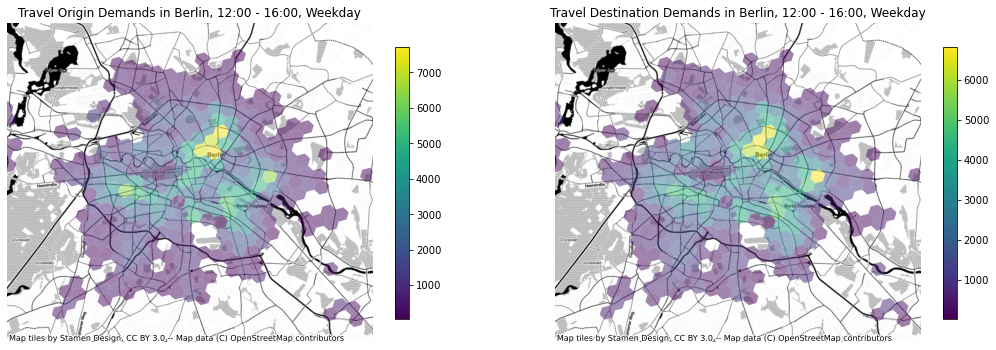

In [162]:
fig, ax = plt.subplots(figsize=(18,10), ncols=2)

demand_start_wm[~demand_start_wm.duplicated(subset=['h3_start_8'])].plot(
    ax=ax[0], column='total_trips_start', alpha=0.5, legend=True, legend_kwds={'shrink': 0.5})
cx.add_basemap(ax[0], source=cx.providers.Stamen.Toner)
ax[0].set_title('Travel Origin Demands in Berlin, 12:00 - 16:00, Weekday')
ax[0].set_xlim(1.47*1e6,1.51*1e6)
ax[0].set_ylim(6.875*1e6, 6.91*1e6)
ax[0].axis('off')

demand_end_wm[~demand_end_wm.duplicated(subset=['h3_end_8'])].plot(
    ax=ax[1], column='total_trips_end', alpha=0.5, legend=True, legend_kwds={'shrink': 0.5})
cx.add_basemap(ax[1], source=cx.providers.Stamen.Toner)
ax[1].set_title('Travel Destination Demands in Berlin, 12:00 - 16:00, Weekday')
ax[1].set_xlim(1.47*1e6,1.51*1e6)
ax[1].set_ylim(6.875*1e6, 6.91*1e6)
ax[1].axis('off')

plt.savefig(os.path.join(DATA_PATH, 'output/figures/demands_1620_weekday_hex8.png'), bbox_inches='tight')
plt.show()